# 1. Imports and other

Raíz

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
print(PROJECT_ROOT)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas


Ruta de figures modeling

In [2]:
FIGURES_MODELING_PATH = PROJECT_ROOT / 'outputs' / 'figures_modeling'
print(FIGURES_MODELING_PATH)

c:\Users\Carlos\Documents\Ingenieria_informatica\Proyectos_datascience\3_prediccion_precios_casas\outputs\figures_modeling


Imports

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 2. Read data

In [4]:
df = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'processed_train.csv')

# 3. Split train/test

In [5]:
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Pipeline

Primero seleccionaremos todas nuestras columnas numéricas y categóricas

In [7]:
num_columns = df.drop(columns=['SalePrice']).select_dtypes(include=['int', 'float']).columns
num_columns

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'LotShape', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual',
       'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', 'HeatingQC', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt',
       'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'PoolQC', 'MiscVal', 'MoSold', 'YrSold'],
      dtype='str')

In [8]:
cat_columns = df.select_dtypes(include='str').columns
cat_columns

Index(['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
       'MasVnrType', 'Foundation', 'BsmtExposure', 'BsmtFinType1',
       'BsmtFinType2', 'Heating', 'CentralAir', 'Electrical', 'Functional',
       'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='str')

## 4.1 Pipelines to impute and transform data

Este pipeline aplica la mediana de los datos aprendidos

In [9]:
pipeline_num_features = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

Este aplica la moda de los datos aprendidos y luego hace one-hot

In [10]:
pipeline_cat_features = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

El ColumnTransformer espera recibir las columnas mencionadas en num_columns/cat_columns, a eso le aplica la lógica de los pipelines anteriores

In [11]:
column_transfomer = ColumnTransformer([
    ('num_features', pipeline_num_features, num_columns),
    ('cat_features', pipeline_cat_features, cat_columns)
])

## 5. Models

Antes de seguir, crearemos un diccionario con todos los modelos que utilizaremos

In [12]:
models_dict = {
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(),
    'KNeighborsRegressor': KNeighborsRegressor(),
    'XGBRegressor': XGBRegressor()
}

## 6. KFold

Utilizaremos KFold para poder evaluar los modelos con distintas distribuciones de los datos

In [13]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# 7. Evaluate models in train

Metricas que queremos evaluar (puede ser una lista, pero colocarlas en un diccionario hace que luego en los resultados, se pueda buscar con el nombre de la llave, lo cual lo hace más sencillo)

In [14]:
METRICS = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

Primero veremos como se comportan los modelos para los datos de entrenamiento

In [15]:
metrics_train_df = pd.DataFrame()

In [16]:
for model in models_dict:
    # Crear pipeline con el modelo actual
    pipeline = Pipeline([
        ('preprocess', column_transfomer),
        ('scaler', StandardScaler()),
        ('model', models_dict[model])
    ])

    # Hacer las 5 particiones y evaluar métricas en cada una
    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=kfold,
        scoring=METRICS
    )

    # Obtener promedios y distribuciones estándar de los resultados
    maes = -results['test_mae']
    mean_mae = np.mean(maes)
    std_mae = np.std(maes)

    rmses = -results['test_rmse']
    mean_rmse = np.mean(rmses)
    std_rmse = np.std(rmses)

    r2 = results['test_r2']
    mean_r2 = np.mean(r2)
    std_r2 = np.std(r2)

    # DataFrame para luego visualizar resultados
    metrics_train_df_to_add = pd.DataFrame({
        'Model': [model],
        'Mean_mae': [mean_mae],
        'Std_mae': [std_mae],
        'Mean_rmse': [mean_rmse],
        'Std_rmse': [std_rmse],
        'Mean_r2': [mean_r2],
        'Std_r2': [std_r2]
    })

    
    metrics_train_df = pd.concat([metrics_train_df, metrics_train_df_to_add])

In [17]:
metrics_train_df

,Model,Mean_mae,Std_mae,Mean_rmse,Std_rmse,Mean_r2,Std_r2
0,LinearRegression,20388.386088,1405.345915,36132.735386,7825.086464,0.773231,0.085464
0,RandomForestRegressor,18158.037512,966.626893,30360.814329,4732.105897,0.842903,0.042250
0,KNeighborsRegressor,26258.626755,2330.162480,42481.471631,4742.962682,0.696382,0.042826
0,XGBRegressor,18686.272656,1786.304906,31877.489453,6380.830841,0.825601,0.059595


# 8. Visualize results of train

Definir colores del proyecto

In [18]:
PROJECT_COLORS = ["#2DD61D", "#3410FF"]

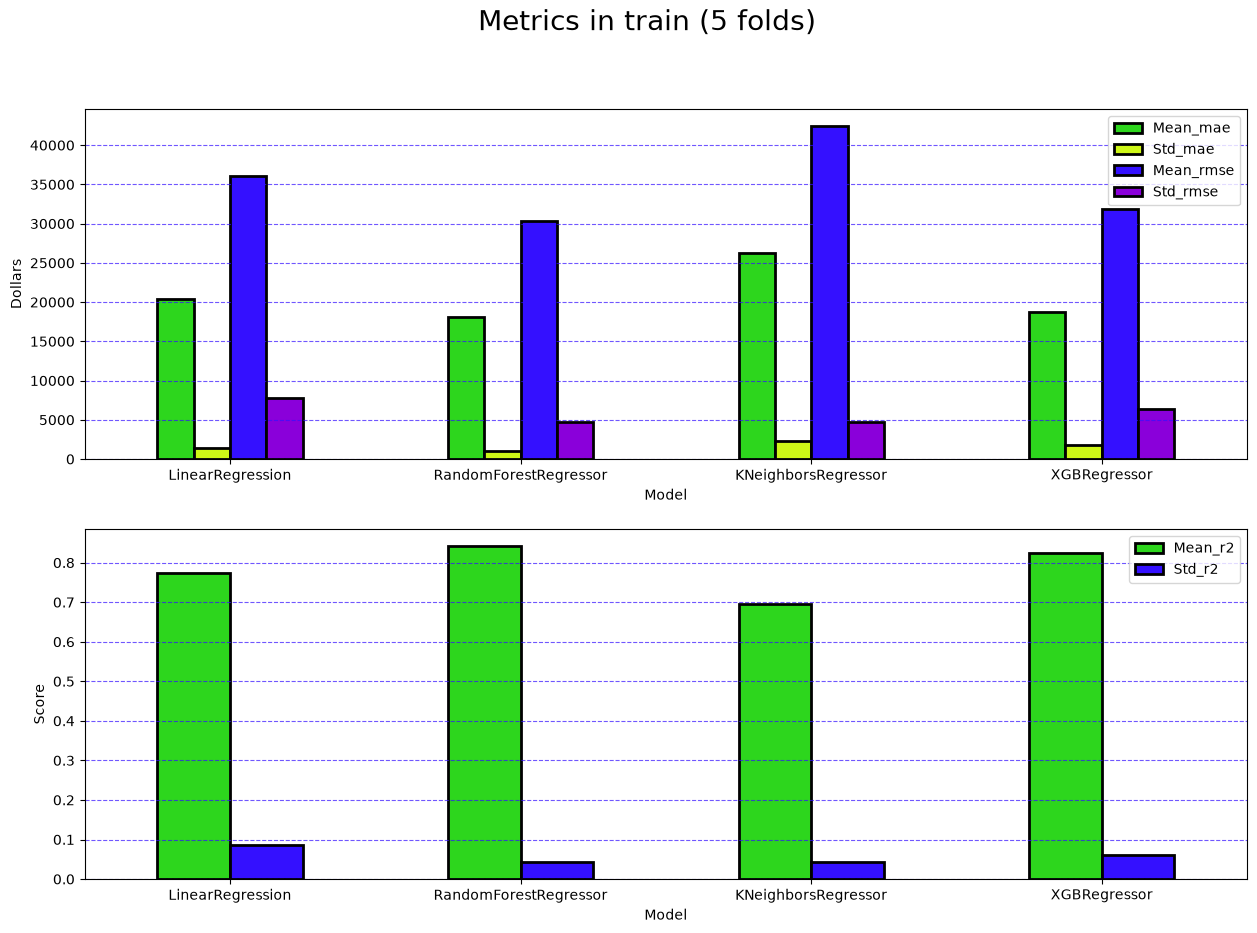

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(15, 10))

metrics_train_df.plot(
    kind='bar',
    x='Model',
    y=['Mean_mae', 'Std_mae', 'Mean_rmse', 'Std_rmse'],
    rot=0,
    edgecolor='black',
    linewidth=2,
    color=[PROJECT_COLORS[0], "#cef717", PROJECT_COLORS[1], "#8a00da"],
    ax=ax[0]
)
ax[0].set_ylabel('Dollars')
ax[0].grid(color=PROJECT_COLORS[1], axis='y', linestyle='--', alpha=0.7)


metrics_train_df.plot(
    kind='bar',
    x='Model',
    y=['Mean_r2', 'Std_r2'],
    rot=0,
    edgecolor='black',
    linewidth=2,
    color=[PROJECT_COLORS[0], PROJECT_COLORS[1]],
    ax=ax[1]
)
ax[1].set_ylabel('Score')
ax[1].grid(color=PROJECT_COLORS[1], axis='y', linestyle='--', alpha=0.7)


fig.suptitle(
    'Metrics in train (5 folds)',
    fontsize=20
)


plt.savefig(FIGURES_MODELING_PATH / '01_metrics_in_train_with_5_folds.png', bbox_inches='tight')
plt.show()

# 9. Visualize results on test

## 9.1 Create Pipelines

In [20]:
pipeline_linear_regression = Pipeline([
    ('preprocess', column_transfomer),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

pipeline_random_forest = Pipeline([
    ('preprocess', column_transfomer),
    ('model', RandomForestRegressor())
])

pipeline_xgboost = Pipeline([
    ('preprocess', column_transfomer),
    ('model', XGBRegressor())
])

pipeline_knn = Pipeline([
    ('preprocess', column_transfomer),
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor())
])

## 9.2 Train models

Primero los guardamos todos en un diccionario para poder hacerlo de forma iterativa

In [21]:
pipelines_models_dict = {
    'LinearRegression': pipeline_linear_regression,
    'RandomForestRegressor': pipeline_random_forest,
    'XGBRegressor': pipeline_xgboost,
    'KNN': pipeline_knn
}

Los entrenamos todos

In [22]:
for model in pipelines_models_dict:
    pipelines_models_dict[model].fit(X_train, y_train)

## 9.3 Predict and visualize

### 9.3.1 MAE and RMSE

Crear un DataFrame para guardar la metricas resultantes

In [23]:
metrics_test_df = pd.DataFrame()

In [24]:
for model in pipelines_models_dict:
    y_pred = pipelines_models_dict[model].predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    metrics_test_df_to_add = pd.DataFrame({
        'Model': [model],
        'Mae': [mae],
        'Rmse': [rmse],
        'R2': [r2]
    })

    metrics_test_df = pd.concat([metrics_test_df, metrics_test_df_to_add])


metrics_test_df

,Model,Mae,Rmse,R2
0,LinearRegression,19539.959568,29068.785279,0.889836
0,RandomForestRegressor,17478.262534,29282.100279,0.888213
0,XGBRegressor,16394.517578,26659.869141,0.907338
0,KNN,25054.482877,44710.302173,0.739384


Visualizar

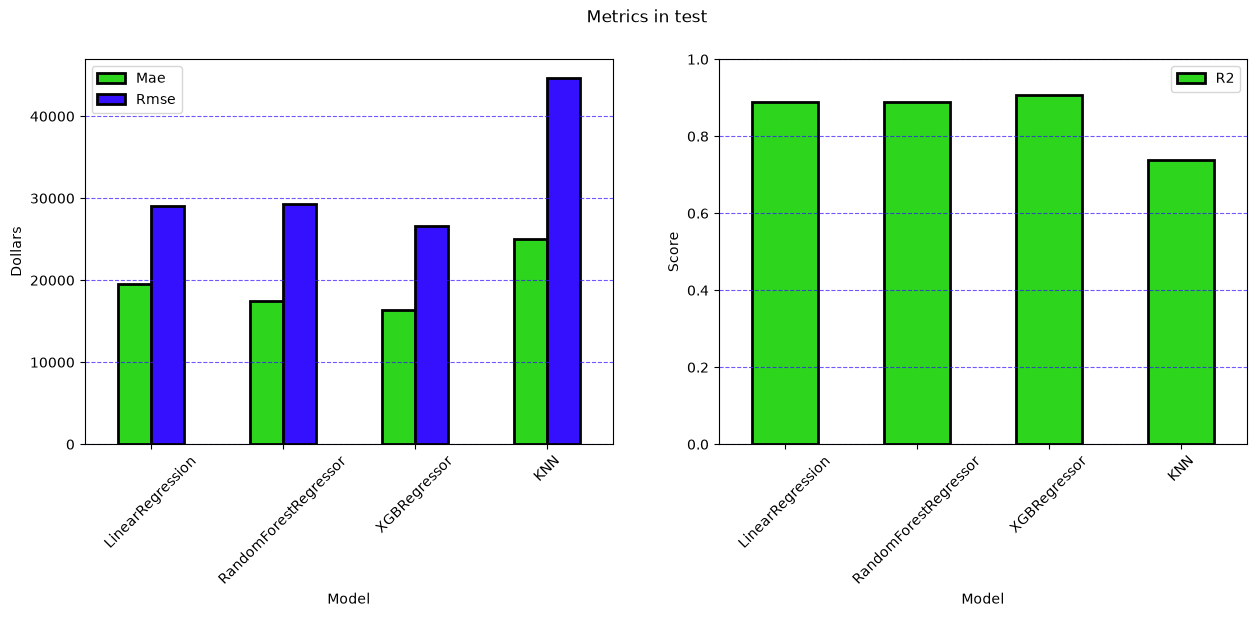

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

metrics_test_df.plot(
    kind='bar',
    x='Model',
    y=['Mae', 'Rmse'],
    rot=45,
    color=[PROJECT_COLORS[0], PROJECT_COLORS[1]],
    edgecolor='black',
    linewidth=2,
    ax=ax[0]
)
ax[0].set_ylabel('Dollars')
ax[0].grid(axis='y', color=PROJECT_COLORS[1], linestyle='--', alpha=0.7)

metrics_test_df.plot(
    kind='bar',
    x='Model',
    y='R2',
    rot=45,
    color=PROJECT_COLORS[0],
    edgecolor='black',
    linewidth=2,
    ax=ax[1]
)
ax[1].set_ylabel('Score')
ax[1].grid(axis='y', color=PROJECT_COLORS[1], linestyle='--', alpha=0.7)
ax[1].set_ylim(0.0, 1.0)

fig.suptitle('Metrics in test')

plt.savefig(FIGURES_MODELING_PATH / '02_metrics_in_test.png')
plt.show()

### 9.3.2 Scatter

La línea diagonal, representa los valores reales, donde los predicho coincide exactamente con lo real

Cuando se marca en el scatter, supongamos que lo predicho es 10000 y el valor real es 10000, es decir deberia pasar exactamente por la línea diagonal

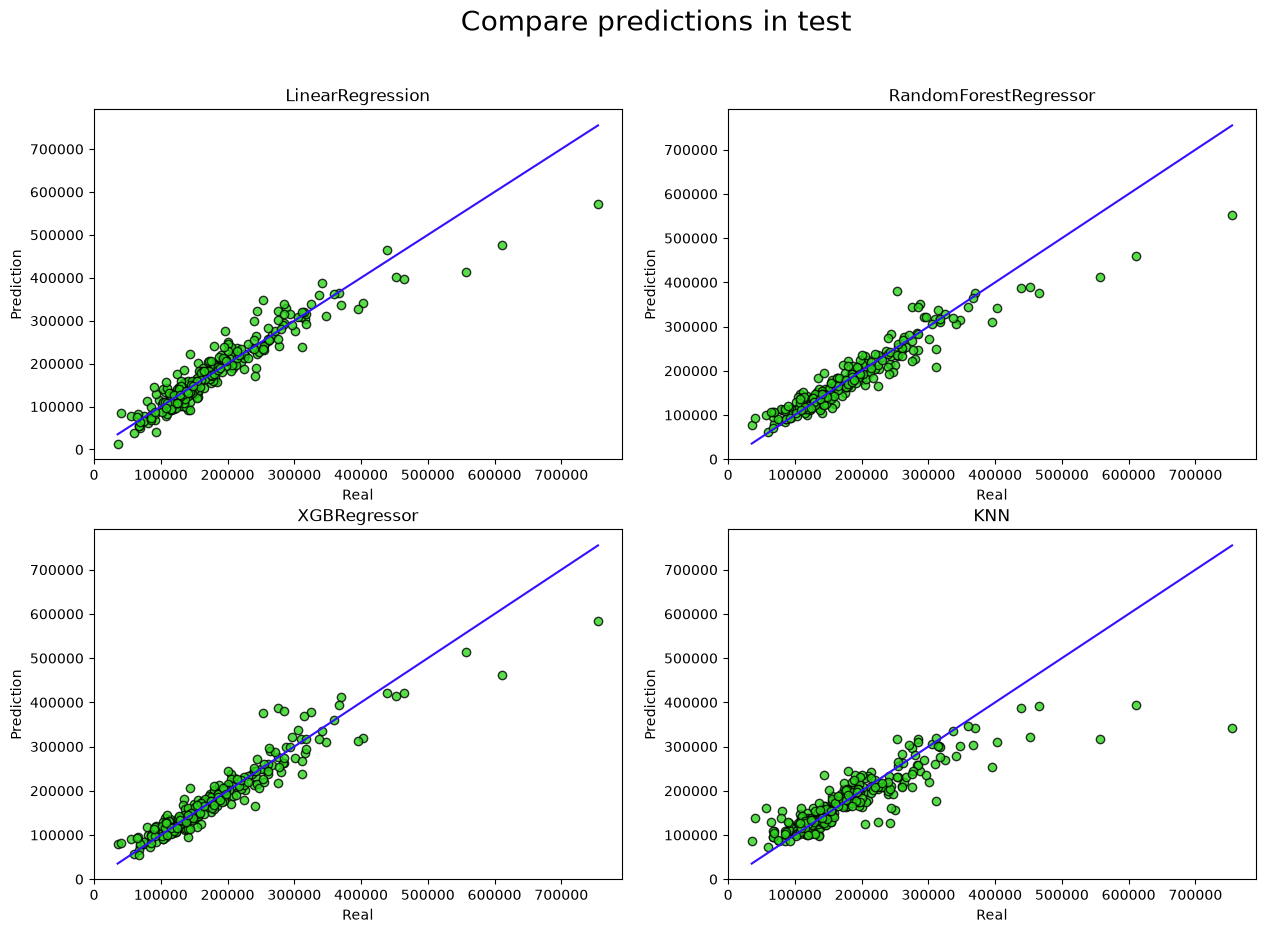

In [26]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

ax_flat = ax.flat

for i, model in enumerate(pipelines_models_dict):
    y_pred = pipelines_models_dict[model].predict(X_test)

    # Linea para marcar los valores reales donde el punto "x" es igual a "y"
    ax_flat[i].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        color=PROJECT_COLORS[1]
    )

    # Marcar puntos donde la "x" es lo predicho e "y" es el valor real
    ax_flat[i].scatter(
        y_test,
        y_pred,
        color=PROJECT_COLORS[0],
        edgecolor='black',
        alpha=0.8
    )

    ax_flat[i].set_xlabel('Real')
    ax_flat[i].set_ylabel('Prediction')
    ax_flat[i].set_title(f'{model}')


fig.suptitle(
    'Compare predictions in test',
    fontsize=20
)


plt.savefig(FIGURES_MODELING_PATH / '03_compare_prediction_vs_real_in_test.png', bbox_inches='tight')
plt.show()

### 9.3.3 Compare in all set

Veremos los resultados predichos y reales para el dataset completo

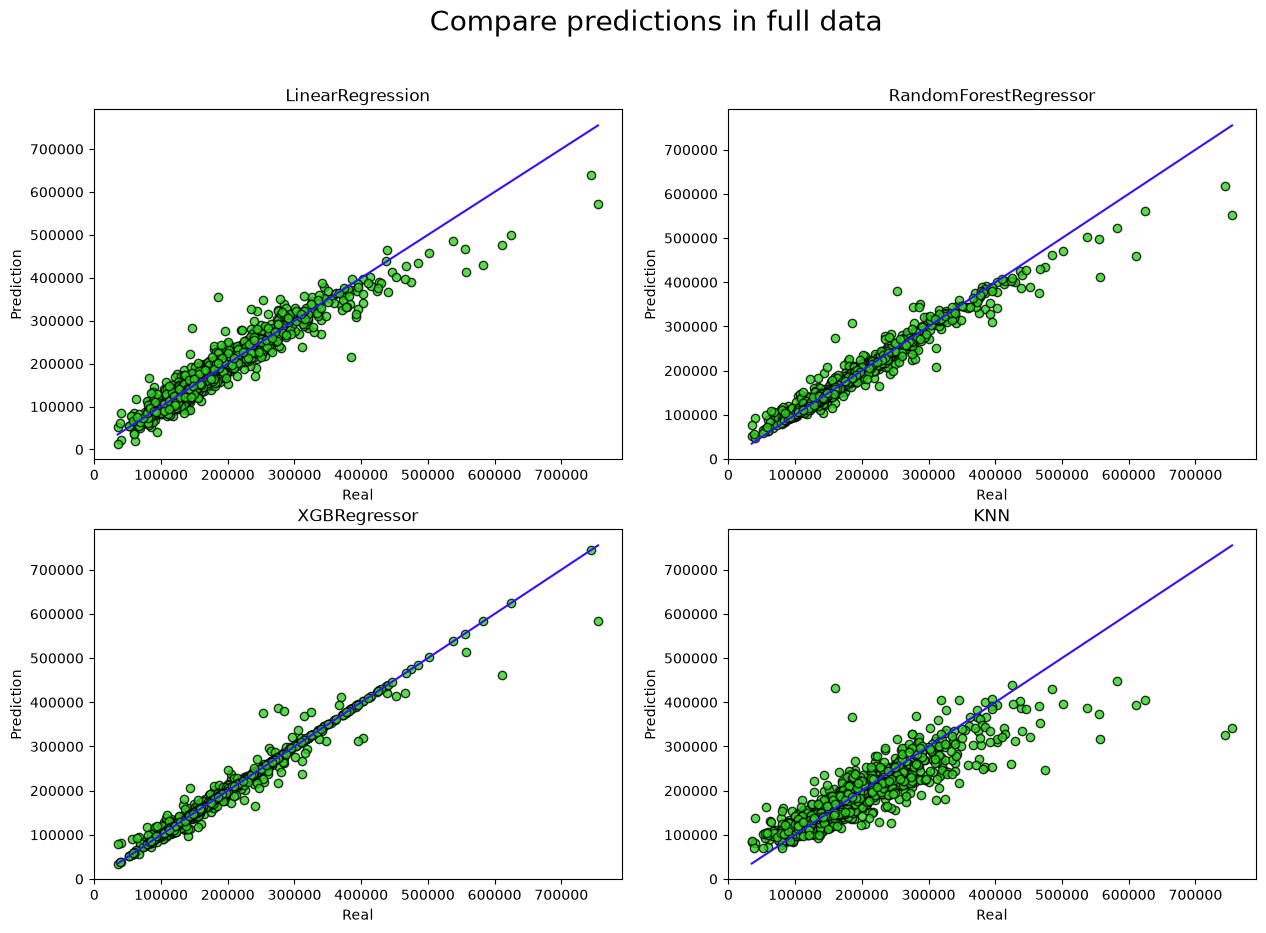

In [73]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

ax_flat = ax.flat

for i, model in enumerate(pipelines_models_dict):
    y_pred_total = pipelines_models_dict[model].predict(X)

    # Linea de reales
    ax_flat[i].plot(
        [y.min(), y.max()],
        [y.min(), y.max()],
        color=PROJECT_COLORS[1]
    )

    # Puntos de reales vs predicciones
    ax_flat[i].scatter(
        y,
        y_pred_total,
        color=PROJECT_COLORS[0],
        edgecolor='black',
        alpha=0.8
    )

    ax_flat[i].set_xlabel('Real')
    ax_flat[i].set_ylabel('Prediction')
    ax_flat[i].set_title(f'{model}')


fig.suptitle(
    'Compare predictions in full data',
    fontsize=20
)

plt.savefig(FIGURES_MODELING_PATH / '04_compare_prediction_vs_real_in_full_data.png', bbox_inches='tight')
plt.show()

# 10. Select best models

Ahora sabemos que los modelos basados en arboles como RandomForestRegressor y XGBRegressor capturan mejor los datos, vamos a aplicar GridSearchCV para encontrar los mejores hiperparámetros de cada uno

## 10.1 RandomForest GridSearch

Parámetros a probar (recordar que está dentro de un pipeline asi que hay que ocupar esa nomenclatura)

In [28]:
param_grid_random_forest = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 4, 6, 8],
    'model__min_samples_leaf': [1, 2, 5, 10]
}

In [29]:
grid_search_random_forest = GridSearchCV(
    estimator=pipeline_random_forest,
    param_grid=param_grid_random_forest,
    cv=kfold,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

## 10.2 XGBoost GridSearch

Parámetros a probar

In [30]:
param_grid_xgboost = {
    'model__n_estimators': [300, 500, 700, 1000],
    'model__max_depth': [2, 3, 5, 7],
    'model__learning_rate': [0.01, 0.04, 0.07, 0.1],
    'model__min_child_weight': [1, 3, 5, 10],
    'model__reg_lambda': [1, 4, 7, 10]
}

In [32]:
grid_search_xgboost = GridSearchCV(
    estimator=pipeline_xgboost,
    param_grid=param_grid_xgboost,
    cv=kfold,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

## 10.3 Train models

Random Forest

In [33]:
grid_search_random_forest.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 4, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and 

XGBoost

In [34]:
grid_search_xgboost.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.01, 0.04, ...], 'model__max_depth': [2, 3, ...], 'model__min_child_weight': [1, 3, ...], 'model__n_estimators': [300, 500, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity

# 11. GridSearch models in test

## 11.1 Mae and Rmse

Predict

In [37]:
y_pred_gridsearch_randomforest = grid_search_random_forest.predict(X_test)
y_pred_gridsearch_xgboost = grid_search_xgboost.predict(X_test)

Save metrics

In [38]:
mae_gridsearch_randomforest = mean_absolute_error(y_test, y_pred_gridsearch_randomforest)
rmse_gridsearch_randomforest = root_mean_squared_error(y_test, y_pred_gridsearch_randomforest)
r2_gridsearch_randomforest = r2_score(y_test, y_pred_gridsearch_randomforest)

mae_gridsearch_xgboost = mean_absolute_error(y_test, y_pred_gridsearch_xgboost)
rmse_gridsearch_xgboost = root_mean_squared_error(y_test, y_pred_gridsearch_xgboost)
r2_gridsearch_xgboost = r2_score(y_test, y_pred_gridsearch_xgboost)

In [40]:
metrics_test_df_gridsearch = pd.DataFrame({
    'Model': ['RandomForestRegressor', 'XGBRegressor'],
    'Mae': [mae_gridsearch_randomforest, mae_gridsearch_xgboost],
    'Rmse': [rmse_gridsearch_randomforest, rmse_gridsearch_xgboost],
    'R2': [r2_gridsearch_randomforest, r2_gridsearch_xgboost]
})

metrics_test_df_gridsearch

,Model,Mae,Rmse,R2
0,RandomForestRegressor,17271.803881,28515.644391,0.893989
1,XGBRegressor,15702.120117,25272.607422,0.916730


Visualize

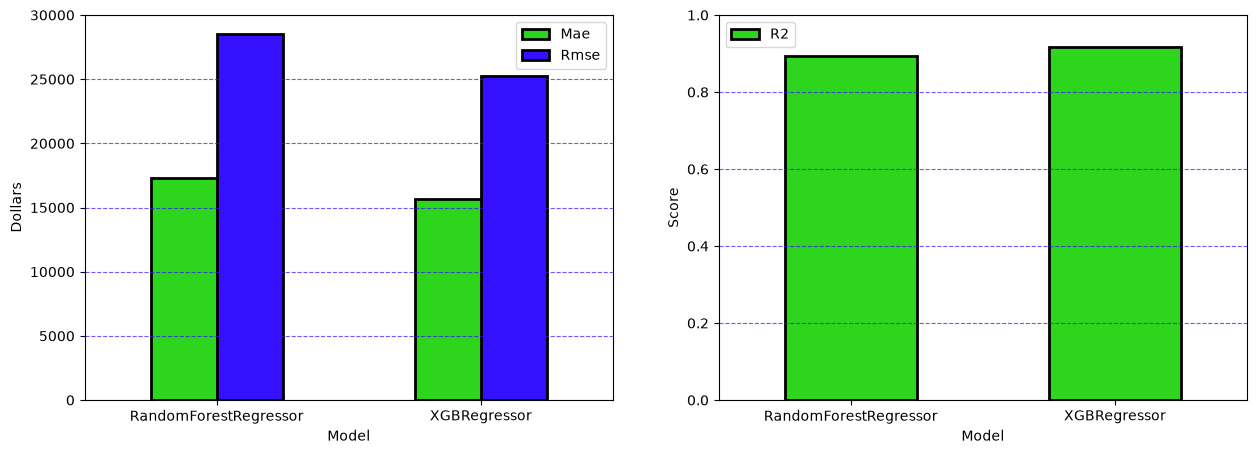

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

metrics_test_df_gridsearch.plot(
    kind='bar',
    x='Model',
    y=['Mae', 'Rmse'],
    color=[PROJECT_COLORS[0], PROJECT_COLORS[1]],
    edgecolor='black',
    linewidth=2,
    rot=0,
    ax=ax[0]
)
ax[0].set_ylabel('Dollars')
ax[0].grid(axis='y', color=PROJECT_COLORS[1], linestyle='--', alpha=0.7)
ax[0].set_ylim(0, 30000)

metrics_test_df_gridsearch.plot(
    kind='bar',
    x='Model',
    y='R2',
    color=PROJECT_COLORS[0],
    edgecolor='black',
    linewidth=2,
    rot=0,
    ax=ax[1]
)
ax[1].set_ylabel('Score')
ax[1].grid(axis='y', color=PROJECT_COLORS[1], linestyle='--', alpha=0.7)
ax[1].set_ylim(0.0, 1.0)


plt.savefig(FIGURES_MODELING_PATH / '05_metrics_in_test_gridsearch_models.png', bbox_inches='tight')
plt.show()

## 11.2 Scatter predictions vs real

Colocar resultados en un diccionario

In [63]:
gridsearch_predictions_dict = {
    'RandomForestRegressor': y_pred_gridsearch_randomforest,
    'XGBRegressor': y_pred_gridsearch_xgboost
}

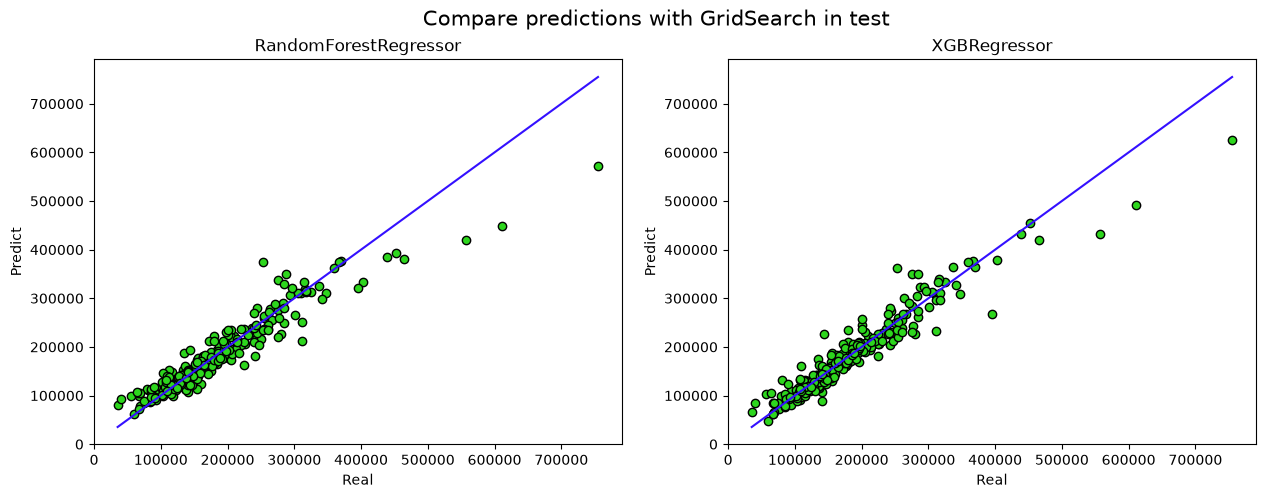

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for i, model in enumerate(gridsearch_predictions_dict):    
    ax[i].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        color=PROJECT_COLORS[1]
    )

    ax[i].scatter(
        y_test,
        gridsearch_predictions_dict[model],
        color=PROJECT_COLORS[0],
        edgecolor='black'
    )

    ax[i].set_xlabel('Real')
    ax[i].set_ylabel('Predict')

    ax[i].set_title(model)

fig.suptitle(
    'Compare predictions with GridSearch in test',
    fontsize=15
)

plt.savefig(FIGURES_MODELING_PATH / '06_compare_prediction_vs_real_gridsearch_models.png', bbox_inches='tight')
plt.show()

Comparación en full data

In [74]:
y_pred_gridsearch_randomforest_total = grid_search_random_forest.predict(X)
y_pred_gridsearch_xgboost_total = grid_search_xgboost.predict(X)

In [75]:
gridsearch_total_predictions_dict = {
    'RandomForestRegressor': y_pred_gridsearch_randomforest_total,
    'XGBRegressor': y_pred_gridsearch_xgboost_total
}

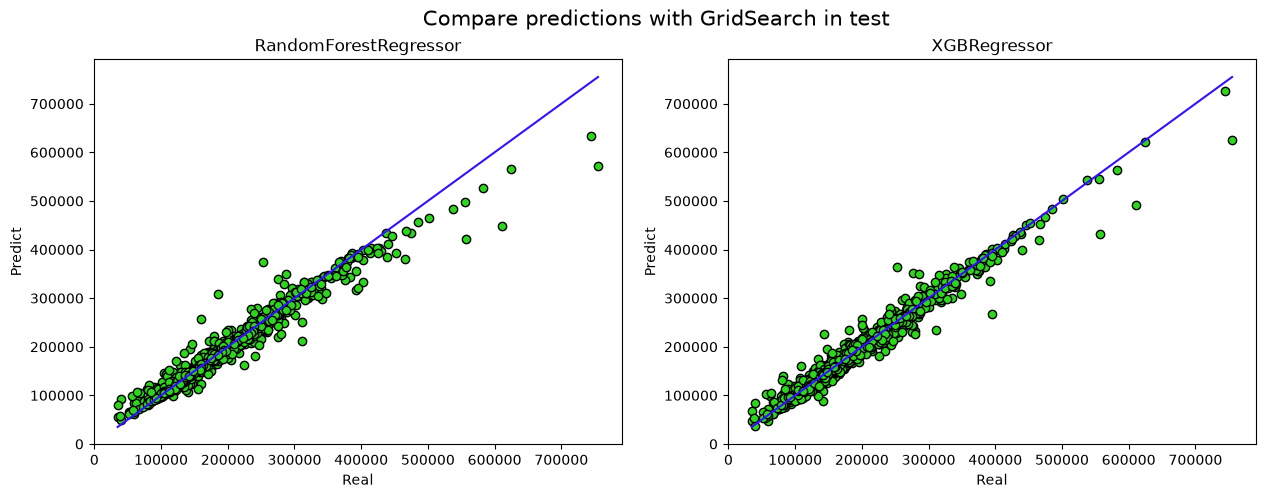

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for i, model in enumerate(gridsearch_total_predictions_dict):    
    ax[i].plot(
        [y.min(), y.max()],
        [y.min(), y.max()],
        color=PROJECT_COLORS[1]
    )

    ax[i].scatter(
        y,
        gridsearch_total_predictions_dict[model],
        color=PROJECT_COLORS[0],
        edgecolor='black'
    )

    ax[i].set_xlabel('Real')
    ax[i].set_ylabel('Predict')

    ax[i].set_title(model)

fig.suptitle(
    'Compare predictions with GridSearch in test',
    fontsize=15
)

plt.savefig(FIGURES_MODELING_PATH / '07_compare_prediction_vs_real_in_full_data_gridsearch_models.png', bbox_inches='tight')
plt.show()